# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Kamal Sangam, Jiaxian Wang, Sam Edwards

**Date:** Nov 9 2026

## Q1. Clean the data and explore it

I check the column types, missing values, duplicate rows, and unrealistic numbers before modeling. For waterfront and view descriptions, a missing value is labeled "Not recorded" rather than assuming the property definitely has no waterfront or view.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

csv_path = Path("data/pierce_county_house_sales.csv")
df = pd.read_csv(csv_path)
print("Original shape:", df.shape)
print("\nColumn types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
display(df.head())

Original shape: (16814, 19)

Column types:
 sale_date                      object
sale_price                      int64
house_square_feet               int64
attic_finished_square_feet      int64
basement_square_feet            int64
attached_garage_square_feet     int64
detached_garage_square_feet     int64
fireplaces                      int64
hvac_description               object
exterior                       object
interior                       object
stories                         int64
roof_cover                     object
year_built                      int64
bedrooms                        int64
bathrooms                       int64
waterfront_type                object
view_quality                   object
utility_sewer                  object
dtype: object

Missing values:
 sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_s

,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


In [2]:
# Remove duplicate rows and records with invalid or unrealistic house values
clean = df.drop_duplicates().copy()
clean["sale_date"] = pd.to_datetime(clean["sale_date"], errors="coerce")

valid = (
    clean["sale_date"].notna()
    & (clean["sale_price"] >= 10000)
    & (clean["house_square_feet"] >= 300)
    & clean["year_built"].between(1800, 2020)
    & (clean["year_built"] <= clean["sale_date"].dt.year)
    & clean["bedrooms"].between(1, 10)
    & clean["bathrooms"].between(1, 8)
    & clean["stories"].between(1, 4)
)
clean = clean.loc[valid].copy()

categorical = ["hvac_description", "exterior", "interior", "roof_cover",
               "waterfront_type", "view_quality", "utility_sewer"]
clean[categorical] = clean[categorical].fillna("Not recorded")
clean["house_age"] = clean["sale_date"].dt.year - clean["year_built"]

print("Rows after cleaning:", len(clean))
print("Rows removed:", len(df) - len(clean))
print("\nSale prices:\n", clean["sale_price"].describe().round(1))
display(clean.head())

Rows after cleaning: 16629
Rows removed: 185

Sale prices:
 count      16629.0
mean      460704.5
std       231771.5
min        10000.0
25%       348000.0
50%       416000.0
75%       522500.0
max      6130000.0
Name: sale_price, dtype: float64


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer,house_age
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,Not recorded,Not recorded,SEWER/SEPTIC INSTALLED,27
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,Not recorded,Not recorded,SEWER/SEPTIC INSTALLED,3
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,Not recorded,Not recorded,SEWER/SEPTIC INSTALLED,55
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,Not recorded,Not recorded,SEWER/SEPTIC INSTALLED,101
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,Not recorded,Not recorded,SEWER/SEPTIC INSTALLED,65


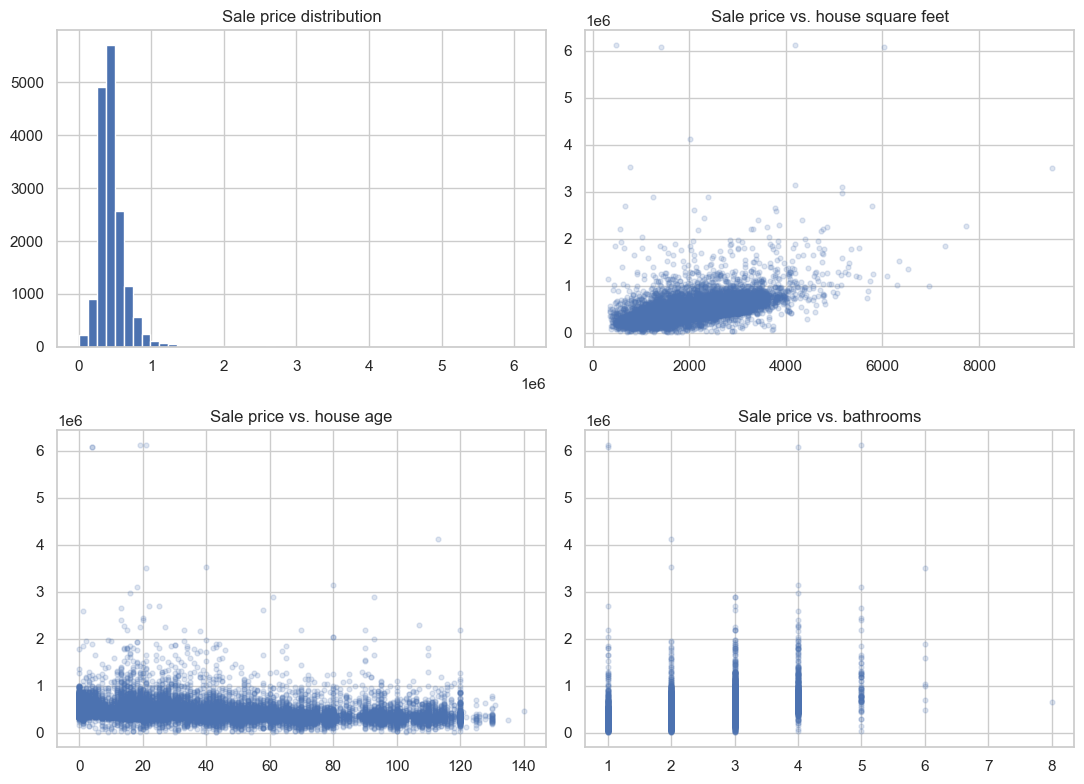

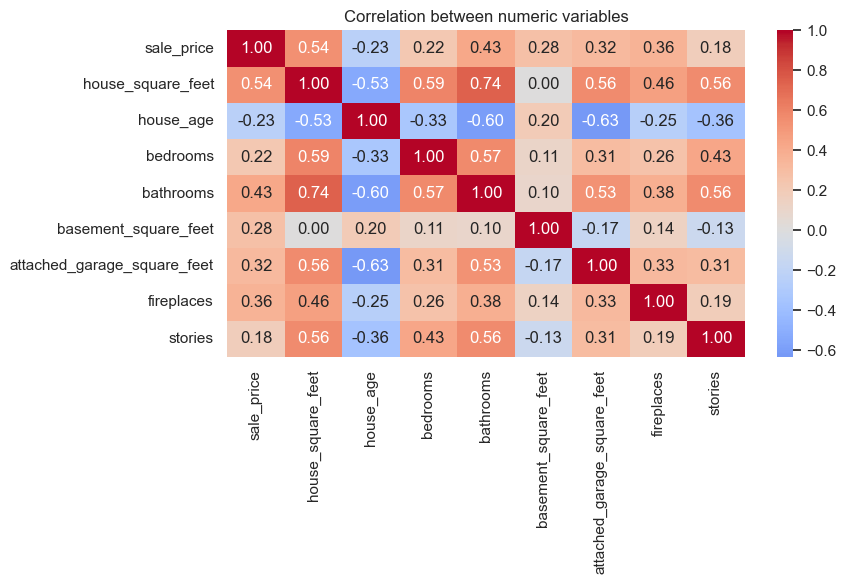

Median sale price: $416,000
Mean sale price: $460,705
Size-price correlation: 0.541


In [3]:
# Price histogram and important numeric relationships
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].hist(clean["sale_price"], bins=50)
axes[0, 0].set_title("Sale price distribution")

for ax, feature in zip(axes.flat[1:], ["house_square_feet", "house_age", "bathrooms"]):
    ax.scatter(clean[feature], clean["sale_price"], alpha=0.18, s=12)
    ax.set_title("Sale price vs. " + feature.replace("_", " "))
plt.tight_layout()
plt.show()

numeric = ["sale_price", "house_square_feet", "house_age", "bedrooms",
           "bathrooms", "basement_square_feet", "attached_garage_square_feet",
           "fireplaces", "stories"]
plt.figure(figsize=(9, 6))
sns.heatmap(clean[numeric].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric variables")
plt.tight_layout()
plt.show()

print("Median sale price: ${:,.0f}".format(clean["sale_price"].median()))
print("Mean sale price: ${:,.0f}".format(clean["sale_price"].mean()))
print("Size-price correlation: {:.3f}".format(clean["house_square_feet"].corr(clean["sale_price"])))

The price distribution has a long right tail, so a small number of expensive houses raise the average above the median. House size appears positively related to price, while the relationships for age and bathrooms are less straightforward. The heatmap helps identify predictors that overlap with one another. I keep plausible expensive properties rather than automatically deleting all outliers.

## Q2. Prepare categorical and numeric features

Linear regression needs numeric input. `pd.get_dummies()` creates 0/1 columns for categories; `drop_first=True` leaves one reference category out to avoid redundant dummy variables. I use house age instead of year built, and leave the date itself out of the predictors. The outcome is always `sale_price` in dollars.

In [4]:
# Use a manageable group of numeric features and all available house categories
numeric_features = ["house_square_feet", "house_age", "bedrooms", "bathrooms",
                    "stories", "fireplaces", "basement_square_feet",
                    "attached_garage_square_feet", "detached_garage_square_feet",
                    "attic_finished_square_feet"]

X = pd.get_dummies(clean[numeric_features + categorical],
                   columns=categorical, drop_first=True, dtype=int)
y = clean["sale_price"]

print("Number of predictors after encoding:", X.shape[1])
print("Any missing predictors?", X.isna().any().any())
display(X.head())

Number of predictors after encoding: 55
Any missing predictors? False


,house_square_feet,house_age,bedrooms,bathrooms,stories,fireplaces,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,attic_finished_square_feet,...,view_quality_View Good,view_quality_View Good +,view_quality_View Lim,view_quality_View Lim +,view_quality_View Lim -,view_quality_View V-Good,utility_sewer_SEWER/SEPTIC AVAIL,utility_sewer_SEWER/SEPTIC INSTALLED,utility_sewer_SEWER/SEPTIC NO,utility_sewer_SEWER/SEPTIC NO PERC
0,2157,27,3,3,2,0,0,528,0,0,...,0,0,0,0,0,0,0,1,0,0
1,2238,3,4,3,2,0,0,396,0,0,...,0,0,0,0,0,0,0,1,0,0
2,1452,55,3,2,1,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,832,101,2,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,1780,65,3,2,1,1,384,484,0,0,...,0,0,0,0,0,0,0,1,0,0


## Q3. Reserve 20% of the data for testing

The same split is used for all models. I fit only on the training rows, and never use the test rows to choose feature transformations or tune Lasso.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Train share: {:.1%}".format(len(X_train) / len(X)))
print("Test share: {:.1%}".format(len(X_test) / len(X)))

Training rows: 13303
Testing rows: 3326
Train share: 80.0%
Test share: 20.0%


## Q4. Fit and compare simple linear models

Model 1 uses house size alone. Model 2 adds age, bedrooms, and bathrooms. Model 3 includes other numeric house features and encoded categories. These are all ordinary linear regressions with no nonlinear features or interactions. RMSE measures typical prediction error in dollars (lower is better), while R² measures explained price variation (higher is better).

In [6]:
def evaluate(name, model, train_features, test_features):
    train_prediction = model.predict(train_features)
    test_prediction = model.predict(test_features)
    return {
        "Model": name,
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_prediction)),
        "Train R2": r2_score(y_train, train_prediction),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_prediction)),
        "Test R2": r2_score(y_test, test_prediction)
    }

simple_features = {
    "Size only": ["house_square_feet"],
    "Size + age + rooms": ["house_square_feet", "house_age", "bedrooms", "bathrooms"],
    "All original features": X_train.columns.tolist()
}

results = []
simple_models = {}
for name, columns in simple_features.items():
    model = LinearRegression()
    model.fit(X_train[columns], y_train)
    simple_models[name] = model
    results.append(evaluate(name, model, X_train[columns], X_test[columns]))

simple_results = pd.DataFrame(results).set_index("Model")
display(simple_results.round(3))
best_simple = simple_results["Test RMSE"].idxmin()
print("Best simple model by test RMSE:", best_simple)
print("Test R2 for this model: {:.3f}".format(simple_results.loc[best_simple, "Test R2"]))

,Train RMSE,Train R2,Test RMSE,Test R2
Model,,,,
Size only,193098.255,0.293,201868.369,0.292
Size + age + rooms,189455.856,0.320,196780.368,0.327
All original features,151719.553,0.564,165332.571,0.525


Best simple model by test RMSE: All original features
Test R2 for this model: 0.525


## Q5. Partial regression plots and possible nonlinearity

A partial regression plot isolates one numeric predictor by removing the linear contributions of the other predictors from both that predictor and the sale price. This is more useful than a basic scatter plot when features are correlated. I use the four-feature simple model here; each numeric variable in this model gets a plot. The dashed line is a straight-line fit, while the solid curve is a quadratic guide. A visible curve suggests that the relationship may not be fully linear.

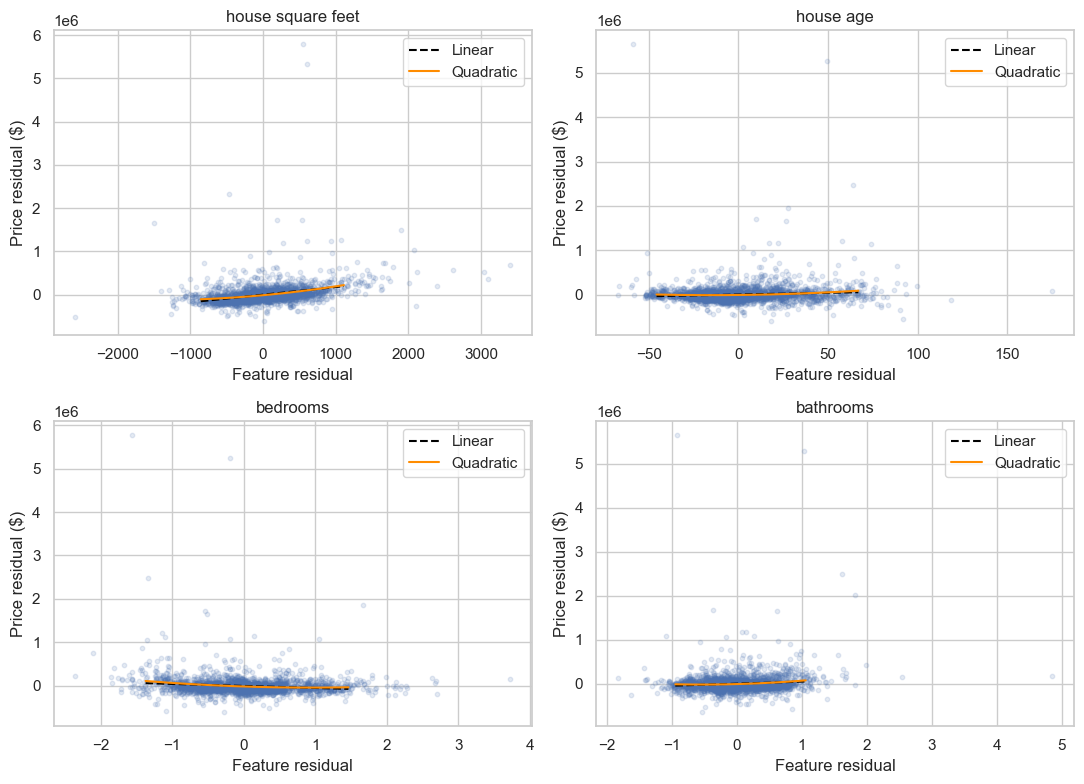

In [7]:
# Make partial regression plots using only training data
partial_features = simple_features["Size + age + rooms"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, feature in zip(axes.flat, partial_features):
    others = [col for col in partial_features if col != feature]
    other_values = X_train[others]

    # Residualize both the target and selected feature against the other predictors
    price_part = y_train - LinearRegression().fit(other_values, y_train).predict(other_values)
    feature_part = X_train[feature] - LinearRegression().fit(
        other_values, X_train[feature]).predict(other_values)

    # Sample points for a readable graph, keeping the trend calculated from all rows
    sample = np.random.default_rng(42).choice(len(feature_part),
                                              size=min(2500, len(feature_part)), replace=False)
    xv = feature_part.to_numpy(dtype=float)
    yv = price_part.to_numpy(dtype=float)
    ax.scatter(xv[sample], yv[sample], alpha=0.15, s=10)

    # Show the straight line and a simple curved guide
    grid = np.linspace(np.percentile(xv, 2), np.percentile(xv, 98), 150)
    line = np.polyfit(xv, yv, 1)
    curve = np.polyfit(xv, yv, 2)
    ax.plot(grid, np.polyval(line, grid), "--", color="black", label="Linear")
    ax.plot(grid, np.polyval(curve, grid), color="darkorange", label="Quadratic")
    ax.set_title(feature.replace("_", " "))
    ax.set_xlabel("Feature residual")
    ax.set_ylabel("Price residual ($)")
    ax.legend()

plt.tight_layout()
plt.show()

These plots show whether there is leftover curvature after accounting for the other variables. Size and age are especially worth testing with nonlinear terms because the price added by another square foot or another year of age may change with the house. Bedrooms and bathrooms are discrete, so their points fall in bands; a curved guide for either should be interpreted cautiously. These are exploratory visual patterns, not formal statistical significance tests.

## Q6. Create a more complex regression model

I add a squared size term to allow the value of extra square footage to change for larger houses, and a squared age term to allow depreciation to vary with age. I also include size × bathrooms and size × waterfront-recorded interactions. The interactions allow the value of house size to depend on another characteristic. I keep the target in dollars so every model's RMSE is directly comparable.

In [8]:
def make_complex_features(features):
    new = features.copy()
    size = new["house_square_feet"] / 1000
    age = new["house_age"]
    new["size_squared"] = size ** 2
    new["age_squared"] = age ** 2
    new["size_x_bathrooms"] = size * new["bathrooms"]

    # An observed waterfront description is not the same as confirmed waterfront
    known_waterfront = clean.loc[features.index, "waterfront_type"].ne("Not recorded").astype(int)
    new["size_x_waterfront_recorded"] = size * known_waterfront
    return new

X_train_complex = make_complex_features(X_train)
X_test_complex = make_complex_features(X_test)

complex_model = LinearRegression()
complex_model.fit(X_train_complex, y_train)
complex_result = evaluate("Complex linear model", complex_model,
                          X_train_complex, X_test_complex)
results.append(complex_result)
comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(3))

change = complex_result["Test RMSE"] - simple_results.loc[best_simple, "Test RMSE"]
print("Complex model test RMSE change vs best simple: ${:,.0f}".format(change))
if change < 0:
    print("The complex model improves test RMSE on this split.")
else:
    print("The complex model does not improve test RMSE on this split.")

,Train RMSE,Train R2,Test RMSE,Test R2
Model,,,,
Size only,193098.255,0.293,201868.369,0.292
Size + age + rooms,189455.856,0.320,196780.368,0.327
All original features,151719.553,0.564,165332.571,0.525
Complex linear model,148882.400,0.580,160006.349,0.555


Complex model test RMSE change vs best simple: $-5,326
The complex model improves test RMSE on this split.


## Q7. Summary and model selection

I compare training and test RMSE to look for overfitting. A much lower training error than test error can mean the model has learned patterns that do not generalize. A model with high error on both can be underfitting. I use test RMSE as the final comparison metric rather than assuming that the most complex model is best.

In [9]:
comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(3))
winner = comparison["Test RMSE"].idxmin()
print("Lowest test RMSE:", winner)
print("Test RMSE: ${:,.0f}".format(comparison.loc[winner, "Test RMSE"]))
print("Test R2: {:.3f}".format(comparison.loc[winner, "Test R2"]))

for name, row in comparison.iterrows():
    gap = row["Test RMSE"] - row["Train RMSE"]
    print("{}: test RMSE is ${:,.0f} {} than training RMSE".format(
        name, abs(gap), "higher" if gap >= 0 else "lower"))

if complex_result["Test RMSE"] > simple_results.loc[best_simple, "Test RMSE"]:
    print("The extra complexity may be fitting training noise or unnecessary patterns.")
else:
    print("The extra terms help predict unseen houses on this train/test split.")

,Train RMSE,Train R2,Test RMSE,Test R2
Model,,,,
Size only,193098.255,0.293,201868.369,0.292
Size + age + rooms,189455.856,0.320,196780.368,0.327
All original features,151719.553,0.564,165332.571,0.525
Complex linear model,148882.400,0.580,160006.349,0.555


Lowest test RMSE: Complex linear model
Test RMSE: $160,006
Test R2: 0.555
Size only: test RMSE is $8,770 higher than training RMSE
Size + age + rooms: test RMSE is $7,325 higher than training RMSE
All original features: test RMSE is $13,613 higher than training RMSE
Complex linear model: test RMSE is $11,124 higher than training RMSE
The extra terms help predict unseen houses on this train/test split.


## Q8. Use Lasso to select predictive features

Lasso shrinks coefficients and can set less useful ones exactly to zero. Because predictors use different units, I standardize them first using only the training data. I select the penalty with five-fold cross-validation on the training set, then fit a `sklearn.linear_model.Lasso` model with that penalty. The test set is used only for final evaluation.

In [10]:
# Standardize using training values only
scaler = StandardScaler()
scaled_train = scaler.fit_transform(X_train_complex)
scaled_test = scaler.transform(X_test_complex)

# Choose the penalty without looking at the test set
lasso_cv = LassoCV(alphas=np.logspace(1, 5, 25), cv=5,
                   max_iter=20000, random_state=42)
lasso_cv.fit(scaled_train, y_train)

lasso = Lasso(alpha=lasso_cv.alpha_, max_iter=20000)
lasso.fit(scaled_train, y_train)

lasso_result = evaluate("Lasso", lasso, scaled_train, scaled_test)
results.append(lasso_result)
print("Chosen alpha:", round(lasso_cv.alpha_, 2))

coefficients = pd.Series(lasso.coef_, index=X_train_complex.columns)
selected = coefficients[coefficients.abs() > 0.01]
print("Selected features:", len(selected), "out of", len(coefficients))
print("\nLargest standardized coefficients by absolute value:")
display(selected.reindex(selected.abs().sort_values(ascending=False).index).head(15).round(2).to_frame("Coefficient"))

final_results = pd.DataFrame(results).set_index("Model")
display(final_results.round(3))
print("Best overall test RMSE:", final_results["Test RMSE"].idxmin())

Chosen alpha: 215.44
Selected features: 55 out of 59

Largest standardized coefficients by absolute value:


,Coefficient
house_square_feet,53783.68
size_x_waterfront_recorded,48521.48
basement_square_feet,41926.17
age_squared,41714.39
house_age,-41301.06
waterfront_type_WF Salt,39314.58
size_squared,26975.57
attached_garage_square_feet,26172.44
size_x_bathrooms,23978.11
utility_sewer_SEWER/SEPTIC INSTALLED,-22813.77


,Train RMSE,Train R2,Test RMSE,Test R2
Model,,,,
Size only,193098.255,0.293,201868.369,0.292
Size + age + rooms,189455.856,0.320,196780.368,0.327
All original features,151719.553,0.564,165332.571,0.525
Complex linear model,148882.400,0.580,160006.349,0.555
Lasso,148955.302,0.579,159933.663,0.556


Best overall test RMSE: Lasso


### Final interpretation

The three ordinary linear models give a baseline for predicting house prices. The partial plots help check where those straight-line assumptions may miss patterns. Adding squared and interaction terms tests whether more flexibility helps, while Lasso tries to reduce unnecessary coefficients. The most useful model is the one with strong performance on withheld houses, not automatically the model with the best training score.

The reported selected Lasso predictors are associations for prediction, not proof that changing a house feature would cause its sale price to change. The randomly held-out data come from the same 2020 sales dataset, so performance on another year or market could differ.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [11]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]